# Asociación entre características sociodemográficas y supervivencia en el Titanic: un análisis exploratorio de datos reproducible

**MCDI503 · Exploración Inteligente para la Ciencia de Datos · Sumativa 1 (Fase 1)**

## I. Identificación del proyecto

| Campo | Detalle |
|---|---|
| Curso | MCDI503 Exploración Inteligente para la Ciencia de Datos (UNAB) |
| Equipo | Grupo 4: Felipe Díaz Toro, Pablo Ríos Passteni, Guillermo Subiabre Chacón y Ninoska Yévenes Hernández |
| Conjunto de datos | `titanic` del repositorio `seaborn-data` (Waskom, s. f.), leído desde una copia local verificada con SHA-256 (`data/raw/titanic.csv`) y, si no está disponible, desde Seaborn como respaldo (ver sección III.1) |
| Propósito general | Identificar, mediante un EDA documentado y reproducible, qué características de los pasajeros se asocian con la supervivencia, y dejar un diagnóstico de calidad del dataset como base para las fases siguientes. |
| Fecha de entrega | 29 de noviembre de 2026 |

**Responsables por sección:** I, II y VIII: Felipe · III y V: Pablo · IV y VII: Guillermo · VI: Ninoska.

### Configuración del entorno y reproducibilidad
Esta celda deja registradas las versiones con las que se ejecutó el análisis y fija la semilla aleatoria. Si alguien reproduce el notebook con otras versiones, puede comparar con esta salida.

In [1]:
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")

print("Python    :", sys.version.split()[0])
print("numpy     :", np.__version__)
print("pandas    :", pd.__version__)
print("seaborn   :", sns.__version__)
print("matplotlib:", matplotlib.__version__)
print("Semilla   :", SEED)

Python    : 3.13.9
numpy     : 2.5.3
pandas    : 3.0.5
seaborn   : 0.13.2
matplotlib: 3.11.1
Semilla   : 42


## II. Contexto y objetivo exploratorio

**Contexto.** El hundimiento del Titanic (abril de 1912) es un caso histórico documentado con registros individuales de pasajeros. Estos registros permiten estudiar cómo se relacionan las características personales y de viaje con la supervivencia. El caso es adecuado para esta fase porque presenta valores faltantes, variables de distinto tipo y posibles valores atípicos.

**Objetivo exploratorio.** Examinar, mediante un análisis exploratorio de datos descriptivo y reproducible, la asociación entre la supervivencia de los pasajeros del Titanic y un conjunto de características sociodemográficas y de viaje (sexo, edad, clase del pasaje, tarifa, acompañantes y puerto de embarque), evaluando previamente la calidad de los datos y documentando las decisiones de preparación adoptadas.

**Preguntas exploratorias iniciales**
1. ¿Cómo se distribuyen la edad, la tarifa y la clase de los pasajeros, y hay valores atípicos? *(Guillermo, sección IV)*
2. ¿Cambia la supervivencia según el sexo y la clase del pasaje? *(Ninoska, sección VI)*
3. ¿Cómo se relaciona la edad con la supervivencia? *(Ninoska, sección VI)*
4. ¿Viajar acompañado (`sibsp`, `parch`, `alone`) se asocia con sobrevivir? *(Guillermo, secciones IV y VI)*
5. ¿Los faltantes de `age` y `deck` se concentran en ciertos grupos? *(Pablo, sección V)*

## III. Carga y revisión inicial de datos
*Responsable: Pablo.* En esta sección se carga el dataset, se verifica que corresponda a la versión de referencia del grupo y se describe su estructura y estado general (tipos, faltantes, duplicados y consistencia). Aquí solo se **diagnostica**: las decisiones sobre lo encontrado se toman en la sección V.

#### III.1 Fuente, versión y carga

| Campo | Valor |
|---|---|
| Fuente | `titanic.csv` del repositorio `mwaskom/seaborn-data` (Waskom, s. f.) |
| URL de descarga | https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv |
| Copia local | `data/raw/titanic.csv` (no se modifica; está excluida del control de versiones) |
| Respaldo | `sns.load_dataset("titanic")`, que se usa solo si no existe la copia local |
| Fecha de descarga | 23 de noviembre de 2026 |
| Tamaño | 57.018 bytes |
| SHA-256 | `81787d320d7f7b03df935e91de8bd19e11d45c5bbcab86ef4d4a76dc91b7d4f2` |

- **Pregunta:** ¿los datos con los que trabajamos son exactamente la versión de referencia del grupo?
- **Acción:** se calcula el hash SHA-256 del contenido (copia local o respaldo de Seaborn), se compara con el valor registrado y se carga con `pandas.read_csv`.
- **Decisión y por qué:** se prioriza una copia local fija porque `sns.load_dataset("titanic")` descarga la versión vigente del repositorio y esta podría cambiar. Si no existe la copia local, se usa Seaborn como respaldo y se verifica el mismo hash, de modo que ambas rutas entregan exactamente los mismos datos. Si el hash no coincide, el notebook se detiene.

In [2]:
import io, hashlib
from pathlib import Path

RUTA_DATOS = Path("../data/raw/titanic.csv")
SHA256_ESPERADO = "81787d320d7f7b03df935e91de8bd19e11d45c5bbcab86ef4d4a76dc91b7d4f2"

if RUTA_DATOS.exists():
    contenido = RUTA_DATOS.read_bytes()
    fuente = f"copia local ({RUTA_DATOS.name})"
else:
    # Respaldo: sin copia local (por ejemplo, otro equipo) se carga desde seaborn-data.
    contenido = sns.load_dataset("titanic").to_csv(index=False).encode("utf-8")
    fuente = "seaborn (sns.load_dataset), respaldo"

sha256 = hashlib.sha256(contenido).hexdigest()
assert sha256 == SHA256_ESPERADO, "Los datos no coinciden con la versión de referencia del grupo."

titanic = pd.read_csv(io.BytesIO(contenido))
print("Fuente       :", fuente)
print("SHA-256      :", sha256)
print("Dimensiones  :", titanic.shape)
titanic.head()

Fuente       : copia local (titanic.csv)
SHA-256      : 81787d320d7f7b03df935e91de8bd19e11d45c5bbcab86ef4d4a76dc91b7d4f2
Dimensiones  : (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


#### III.2 Estructura y tipos de variables
- **Pregunta:** ¿qué representa cada fila y de qué tipo es cada variable?
- **Acción:** se revisa `info()` y se construye una tabla con el tipo de dato, el número de valores distintos, los faltantes y un ejemplo por columna.
- **Decisión y por qué:** además del tipo de dato de pandas, cada variable se clasifica según su tipo analítico (binaria, nominal, ordinal, discreta o continua), porque ese tipo determina el resumen y el gráfico adecuados en las secciones siguientes.

In [3]:
titanic.info()

estructura = pd.DataFrame({
    "dtype": titanic.dtypes.astype(str),
    "n_unicos": titanic.nunique(dropna=True),
    "n_faltantes": titanic.isna().sum(),
    "pct_faltantes": (titanic.isna().mean() * 100).round(1),
    "ejemplo": titanic.apply(lambda s: s.dropna().iloc[0]),
})
estructura

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


,dtype,n_unicos,n_faltantes,pct_faltantes,ejemplo
survived,int64,2,0,0.0,0
pclass,int64,3,0,0.0,3
sex,str,2,0,0.0,male
age,float64,88,177,19.9,22.0
sibsp,int64,7,0,0.0,1
parch,int64,7,0,0.0,0
fare,float64,248,0,0.0,7.25
embarked,str,3,2,0.2,S
class,str,3,0,0.0,Third
who,str,3,0,0.0,man


**Diccionario de variables**

| Variable | Descripción | Tipo analítico | Observación |
|---|---|---|---|
| `survived` | Sobrevivió (0 = no, 1 = sí) | Binaria (variable objetivo) | |
| `pclass` | Clase del pasaje (1, 2, 3) | Categórica ordinal | Se almacena como entero |
| `sex` | Sexo del pasajero | Categórica nominal | |
| `age` | Edad en años | Numérica continua | Con faltantes |
| `sibsp` | N.º de hermanos o cónyuges a bordo | Numérica discreta | |
| `parch` | N.º de padres o hijos a bordo | Numérica discreta | |
| `fare` | Tarifa pagada | Numérica continua | |
| `embarked` | Puerto de embarque (C, Q, S) | Categórica nominal | Con faltantes |
| `deck` | Cubierta (A–G) | Categórica nominal | Con faltantes |
| `class` | Clase en texto | Redundante con `pclass` | Se verifica en III.5 |
| `who` | Hombre, mujer o niño | Derivada de `sex` y `age` | Se verifica en III.5 |
| `adult_male` | Es hombre adulto | Derivada de `who` | Se verifica en III.5 |
| `embark_town` | Puerto en texto | Redundante con `embarked` | Se verifica en III.5 |
| `alive` | Sobrevivió en texto | Redundante con `survived` | Se verifica en III.5 |
| `alone` | Viajaba sin familiares | Derivada de `sibsp` y `parch` | Se verifica en III.5 |

- **Resultado:** cada fila corresponde a un pasajero; hay 891 filas y 15 columnas (4 enteras, 2 decimales, 7 de texto y 2 booleanas). Con pandas 3 las columnas de texto se leen con el tipo `str`. `pclass` está almacenada como número, pero conceptualmente es ordinal, lo que conviene tener en cuenta al resumirla.

#### III.3 Valores faltantes
- **Pregunta:** ¿cuántos valores faltan y en qué variables?
- **Acción:** se cuentan los faltantes por columna y su porcentaje sobre el total de filas.
- **Decisión y por qué:** se reportan solo las columnas con faltantes; su patrón (pregunta 5) se analiza en la sección V, antes de decidir cómo tratarlos.

In [4]:
faltantes = (
    titanic.isna().sum().to_frame("n_faltantes")
    .assign(pct_faltantes=lambda d: (d["n_faltantes"] / len(titanic) * 100).round(1))
    .query("n_faltantes > 0")
    .sort_values("n_faltantes", ascending=False)
)
faltantes

,n_faltantes,pct_faltantes
deck,688,77.2
age,177,19.9
embarked,2,0.2
embark_town,2,0.2


- **Resultado:** faltan datos en cuatro columnas: `deck` (688; 77,2 %), `age` (177; 19,9 %), `embarked` y `embark_town` (2 cada una; 0,2 %, en los mismos dos registros). La magnitud en `deck` sugiere que su uso analítico será limitado.

#### III.4 Filas duplicadas
- **Pregunta:** ¿existen filas repetidas y cómo son?
- **Acción:** se cuentan las filas idénticas en las 15 columnas y se caracterizan los grupos que forman.
- **Decisión y por qué:** en esta etapa solo se cuantifican; la decisión se toma en la sección V, porque el dataset no tiene un identificador de pasajero que permita confirmar si son registros repetidos.

In [5]:
mask_dup = titanic.duplicated(keep=False)
grupos_dup = titanic[mask_dup].groupby(list(titanic.columns), dropna=False).size()

print("Filas repetidas (sin contar la primera aparición):", titanic.duplicated().sum())
print("Filas involucradas en algún duplicado            :", mask_dup.sum())
print("Grupos de filas idénticas                        :", len(grupos_dup))
print("Tamaño del grupo más grande                      :", grupos_dup.max())
print("Filas involucradas sin edad registrada           :", titanic.loc[mask_dup, "age"].isna().sum())
print("\nFilas involucradas por clase:")
print(titanic.loc[mask_dup, "pclass"].value_counts().sort_index().to_string())

Filas repetidas (sin contar la primera aparición): 107
Filas involucradas en algún duplicado            : 160
Grupos de filas idénticas                        : 53
Tamaño del grupo más grande                      : 13
Filas involucradas sin edad registrada           : 93

Filas involucradas por clase:
pclass
1      4
2     31
3    125


- **Resultado:** hay 107 filas repetidas; en total, 160 filas forman parte de 53 grupos idénticos (el mayor reúne 13 filas). La mayoría corresponde a tercera clase (125 de 160) y a registros sin edad (93 de 160), es decir, perfiles muy comunes con pocas columnas distintivas.

#### III.5 Consistencia, dominios y rangos
- **Pregunta:** ¿las columnas derivadas son coherentes con sus columnas de origen? ¿hay categorías incoherentes o valores fuera de rango?
- **Acción:** se verifican las equivalencias entre columnas, se listan las categorías de las variables de texto y se revisan mínimos y máximos de las numéricas.
- **Decisión y por qué:** se comprueban las equivalencias con código en vez de suponerlas, porque de ese resultado depende la decisión de eliminar columnas redundantes en la sección V.

In [6]:
inicial_puerto = titanic["embark_town"].str[0]
chequeos = pd.Series({
    "class equivale a pclass": titanic["class"].map({"First": 1, "Second": 2, "Third": 3}).eq(titanic["pclass"]).all(),
    "alive equivale a survived": titanic["alive"].map({"no": 0, "yes": 1}).eq(titanic["survived"]).all(),
    "embark_town equivale a embarked": inicial_puerto.fillna("-").eq(titanic["embarked"].fillna("-")).all(),
    "alone equivale a sibsp + parch == 0": titanic["alone"].eq(titanic["sibsp"] + titanic["parch"] == 0).all(),
    "adult_male equivale a who == 'man'": titanic["adult_male"].eq(titanic["who"] == "man").all(),
    "who == 'child' equivale a age < 16": (titanic["who"] == "child").eq(titanic["age"] < 16).all(),
}, name="se_cumple")
display(chequeos.to_frame())

print("Categorías de las variables de texto:")
for col in ["sex", "embarked", "deck", "who"]:
    print(f"  {col}: {titanic[col].value_counts(dropna=False).to_dict()}")

print("\nRangos de las variables numéricas:")
display(titanic[["age", "fare", "sibsp", "parch"]].agg(["min", "max"]))

edad = titanic["age"].dropna()
print("Edades menores de 1 año (con decimales):", (edad < 1).sum())
print("Edades terminadas en ,5 (desde 1 año)  :", ((edad >= 1) & (edad % 1 == 0.5)).sum())
print("Pasajeros con fare == 0                :", (titanic["fare"] == 0).sum())
print("Sin edad, clasificados por who como    :", titanic.loc[titanic["age"].isna(), "who"].value_counts().to_dict())

,se_cumple
class equivale a pclass,True
alive equivale a survived,True
embark_town equivale a embarked,True
alone equivale a sibsp + parch == 0,True
adult_male equivale a who == 'man',True
who == 'child' equivale a age < 16,True


Categorías de las variables de texto:
  sex: {'male': 577, 'female': 314}
  embarked: {'S': 644, 'C': 168, 'Q': 77, nan: 2}
  deck: {nan: 688, 'C': 59, 'B': 47, 'D': 33, 'E': 32, 'A': 15, 'F': 13, 'G': 4}
  who: {'man': 537, 'woman': 271, 'child': 83}

Rangos de las variables numéricas:


,age,fare,sibsp,parch
min,0.42,0.0000,0,0
max,80.00,512.3292,8,6


Edades menores de 1 año (con decimales): 7
Edades terminadas en ,5 (desde 1 año)  : 18
Pasajeros con fare == 0                : 15
Sin edad, clasificados por who como    : {'man': 124, 'woman': 53}


- **Resultado:** las seis equivalencias se cumplen en el 100 % de las filas, por lo que `class`, `alive`, `embark_town`, `adult_male`, `who` y `alone` no aportan información nueva. Las categorías de texto no presentan errores de escritura. Los rangos son plausibles: `age` va de 0,42 a 80 años (7 menores de un año con decimales y 18 edades terminadas en ,5), `fare` va de 0 a 512,33, y `sibsp` (máx. 8) y `parch` (máx. 6) son compatibles con familias numerosas. Quedan dos alertas: 15 pasajeros con `fare` igual a 0, que no necesariamente son errores, y que `who` asigna “man” o “woman” a los 177 pasajeros sin edad, por lo que nunca los clasifica como niños.

## IV. Exploración preliminar
*Responsable: Guillermo.* Debe incluir: resúmenes descriptivos iniciales, revisión de las variables relevantes y visualizaciones. Cubre las preguntas 1 y 4 (distribuciones, atípicos con regla IQR, acompañantes). Escribir una o dos frases de lectura por gráfico, con lenguaje prudente.

**Bloque trazable** (repetir por cada pregunta o decisión):
- **Pregunta:** ¿...?
- **Acción:** qué se hizo (celda de código siguiente).
- **Decisión y por qué:** qué se decidió y su justificación.
- **Resultado:** qué se observó (1–2 frases, con lenguaje prudente).

In [7]:
# TODO (Guillermo): estadísticas descriptivas, distribuciones, categóricas y outliers con IQR

## V. Decisiones y transformaciones iniciales
*Responsable: Pablo.* A partir del diagnóstico de la sección III, aquí se analiza el patrón de los faltantes (pregunta 5), se documentan las decisiones adoptadas y se construye la tabla de trabajo `titanic_eda`. El dataset original (`titanic`) no se modifica.

#### V.1 Patrón de los valores faltantes (pregunta 5)
- **Pregunta:** ¿los faltantes de `age` y `deck` se concentran en ciertos grupos?
- **Acción:** se calcula el porcentaje de faltantes de `age` y `deck` dentro de cada categoría de `pclass`, `sex`, `survived` y `embarked`.
- **Decisión y por qué:** se comparan porcentajes dentro de cada grupo y no conteos, porque los grupos tienen tamaños muy distintos (por ejemplo, 491 pasajeros en tercera clase y 184 en segunda).

In [8]:
indicadores = titanic.assign(age_faltante=titanic["age"].isna(), deck_faltante=titanic["deck"].isna())

tablas = []
for var in ["pclass", "sex", "survived", "embarked"]:
    t = indicadores.groupby(var, dropna=False).agg(
        n=("age_faltante", "size"),
        pct_age_faltante=("age_faltante", "mean"),
        pct_deck_faltante=("deck_faltante", "mean"),
    )
    t[["pct_age_faltante", "pct_deck_faltante"]] = (t[["pct_age_faltante", "pct_deck_faltante"]] * 100).round(1)
    t.index = pd.MultiIndex.from_product([[var], t.index.astype(str)], names=["variable", "categoria"])
    tablas.append(t)

patron_faltantes = pd.concat(tablas)
patron_faltantes

n  pct_age_faltante  pct_deck_faltante
variable categoria                                          
pclass   1          216              13.9               19.0
         2          184               6.0               91.3
         3          491              27.7               97.6
sex      female     314              16.9               69.1
         male       577              21.5               81.6
survived 0          549              22.8               87.8
         1          342              15.2               60.2
embarked C          168              22.6               58.9
         Q           77              63.6               94.8
         S          644              14.0               80.1
         nan          2               0.0                0.0

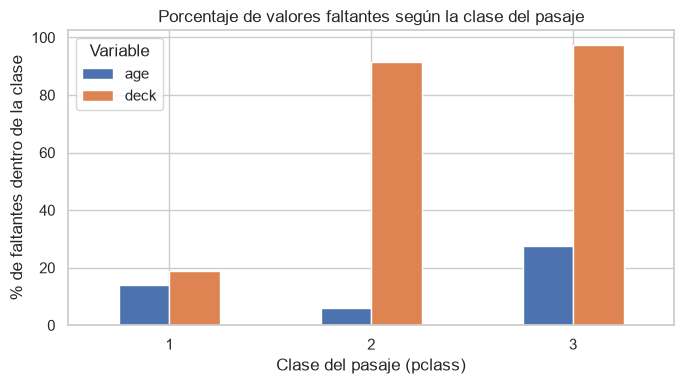

In [9]:
pct_por_clase = indicadores.groupby("pclass")[["age_faltante", "deck_faltante"]].mean() * 100

ax = pct_por_clase.rename(columns={"age_faltante": "age", "deck_faltante": "deck"}).plot.bar(figsize=(7, 4), rot=0)
ax.set_title("Porcentaje de valores faltantes según la clase del pasaje")
ax.set_xlabel("Clase del pasaje (pclass)")
ax.set_ylabel("% de faltantes dentro de la clase")
ax.legend(title="Variable")
plt.tight_layout()
plt.show()

- **Resultado:** los faltantes no se distribuyen de forma pareja.
  - En `age` faltan el 27,7 % de los registros de tercera clase, frente al 13,9 % en primera y al 6,0 % en segunda. La ausencia es mayor entre quienes embarcaron en Queenstown (63,6 %) y entre quienes no sobrevivieron (22,8 % frente a 15,2 %).
  - En `deck` faltan el 97,6 % de los registros de tercera clase y el 91,3 % de segunda, frente al 19,0 % en primera. En la práctica, la cubierta se registró casi solo para primera clase.

  Esto sugiere que la ausencia **no es completamente aleatoria**: se asocia con la clase, el puerto y la supervivencia. Por eso, eliminar los registros incompletos o imputar un valor único podría sesgar el análisis.

#### V.2 Decisiones adoptadas

| Aspecto | Decisión | Justificación |
|---|---|---|
| Filas duplicadas (107) | **Se conservan** | No hay identificador de pasajero. Con solo 15 columnas, dos pasajeros distintos de perfil común (por ejemplo, hombres de tercera clase, sin edad registrada y con la misma tarifa) pueden tener filas idénticas; eliminarlas reduciría artificialmente esos perfiles. |
| `age` (177 faltantes) | **No se imputa** en esta fase; se agrega el indicador `age_missing` | El patrón de V.1 muestra que la ausencia se asocia con la clase y la supervivencia. Imputar con un valor único deformaría la distribución de la edad. Los análisis de edad usarán los casos disponibles, declarándolo. La imputación se evaluará en la fase de limpieza (Sumativa 2). |
| `deck` (688 faltantes) | **No se imputa**; se conserva y se agrega el indicador `deck_known` | Con un 77,2 % de faltantes, concentrados en segunda y tercera clase, cualquier imputación sería mayoritariamente inventada. Se mantiene solo como variable descriptiva de primera clase. |
| `embarked` (2 faltantes) | **Se mantiene como faltante** | Representa el 0,2 % de los registros y no altera los resultados; se excluyen solo en los análisis que usen el puerto. |
| Columnas redundantes | **Se excluyen de la tabla de trabajo** `class`, `alive`, `embark_town`, `adult_male` y `who` | Se verificó en III.5 que replican otras columnas. `who` además oculta los faltantes de edad, porque clasifica como adultos a quienes no tienen edad registrada. `alone` se conserva porque la usa la pregunta 4. |
| Tipos de datos | `sex`, `embarked` y `deck` pasan a categóricas; `pclass` pasa a categórica ordenada (1 < 2 < 3) | Refleja su tipo analítico (diccionario de III.2) y evita tratarlas como números o texto libre. `survived` se mantiene como 0/1 para que su media sea directamente la tasa de supervivencia. |
| Valores atípicos (`fare`, `sibsp`) | **No se modifican** en esta sección | Son valores plausibles (III.5). Su análisis con la regla IQR corresponde a la sección IV. |

#### V.3 Transformaciones y variables derivadas
- **Pregunta:** ¿cómo dejar una tabla de trabajo coherente con las decisiones anteriores, sin alterar los datos originales?
- **Acción:** se crea `titanic_eda` como copia de `titanic`, se eliminan las columnas redundantes, se ajustan los tipos y se agregan tres variables derivadas:
  - `family_size = sibsp + parch + 1`: número de personas del grupo familiar a bordo, incluido el pasajero. Resume en una sola variable la información de acompañantes (pregunta 4).
  - `age_missing`: `True` si no se registró la edad. Permite seguir analizando a esos pasajeros sin imputar.
  - `deck_known`: `True` si se registró la cubierta. Resume una variable con un 77 % de faltantes.
- **Decisión y por qué:** se trabaja sobre una copia para que el original siga disponible y cualquier transformación pueda rehacerse. Se incluyen validaciones (`assert`) para que el notebook se detenga si alguna transformación no produce lo esperado.

In [10]:
COLUMNAS_REDUNDANTES = ["class", "alive", "embark_town", "adult_male", "who"]

titanic_eda = titanic.drop(columns=COLUMNAS_REDUNDANTES).copy()

# Tipos según su naturaleza analítica
titanic_eda["pclass"] = pd.Categorical(titanic_eda["pclass"], categories=[1, 2, 3], ordered=True)
for col in ["sex", "embarked", "deck"]:
    titanic_eda[col] = titanic_eda[col].astype("category")

# Variables derivadas
titanic_eda["family_size"] = titanic_eda["sibsp"] + titanic_eda["parch"] + 1
titanic_eda["age_missing"] = titanic_eda["age"].isna()
titanic_eda["deck_known"] = titanic_eda["deck"].notna()

# Validaciones
assert titanic.shape == (891, 15), "El dataset original no debe modificarse."
assert len(titanic_eda) == len(titanic), "No se deben eliminar filas."
assert titanic_eda["alone"].eq(titanic_eda["family_size"] == 1).all(), "family_size no es coherente con alone."
assert titanic_eda["age_missing"].sum() == titanic["age"].isna().sum()

print("Original     :", titanic.shape)
print("Tabla trabajo:", titanic_eda.shape)
titanic_eda.info()

Original     : (891, 15)
Tabla trabajo: (891, 13)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    category
 2   sex          891 non-null    category
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    category
 8   deck         203 non-null    category
 9   alone        891 non-null    bool    
 10  family_size  891 non-null    int64   
 11  age_missing  891 non-null    bool    
 12  deck_known   891 non-null    bool    
dtypes: bool(3), category(4), float64(2), int64(4)
memory usage: 48.2 KB


In [11]:
print("Distribución de family_size:")
print(titanic_eda["family_size"].value_counts().sort_index().to_string())

print("\nTasa de supervivencia según disponibilidad del dato:")
display(pd.concat(
    {ind: titanic_eda.groupby(ind)["survived"].agg(n="size", tasa_supervivencia="mean").rename_axis("valor")
     for ind in ["age_missing", "deck_known"]},
    names=["indicador"],
).round(3))

Distribución de family_size:
family_size
1     537
2     161
3     102
4      29
5      15
6      22
7      12
8       6
11      7

Tasa de supervivencia según disponibilidad del dato:


n  tasa_supervivencia
indicador   valor                         
age_missing False  714               0.406
            True   177               0.294
deck_known  False  688               0.299
            True   203               0.670

- **Resultado:** la tabla de trabajo `titanic_eda` conserva los 891 pasajeros y queda con 13 columnas (10 originales y 3 derivadas); el dataset original permanece intacto (891 × 15).
  - `family_size` va de 1 a 11; 537 pasajeros (60,3 %) viajaban solos, lo que coincide con `alone`.
  - La tasa de supervivencia es menor entre quienes no tienen edad registrada (29,4 % frente a 40,6 %) y mucho mayor entre quienes tienen cubierta registrada (67,0 % frente a 29,9 %). Esto último refleja, probablemente, que la cubierta se registró casi solo en primera clase, más que un efecto propio de la cubierta. Estas diferencias son descriptivas y no implican causalidad.
- **Uso en las secciones siguientes:** la sección VI puede trabajar sobre `titanic_eda`; los análisis de `age` deben declarar que excluyen los 177 registros sin edad.

## VI. Resultados e interpretación inicial
*Responsable: Ninoska.* Debe incluir: resultados de esta primera implementación, interpretación breve de patrones y relación explícita entre las preguntas exploratorias y los resultados. Cubre las preguntas 2 y 3 (supervivencia por sexo, clase y edad).

**Bloque trazable** (repetir por cada pregunta o decisión):
- **Pregunta:** ¿...?
- **Acción:** qué se hizo (celda de código siguiente).
- **Decisión y por qué:** qué se decidió y su justificación.
- **Resultado:** qué se observó (1–2 frases, con lenguaje prudente).

In [12]:
# TODO (Ninoska): supervivencia por sexo y clase; relación entre edad y supervivencia

## VII. Supuestos y limitaciones
*Responsable: Guillermo.* Debe incluir: supuestos considerados durante el análisis, limitaciones en los datos, el proceso o el alcance, y aspectos pendientes que condicionan las fases posteriores.

**Supuestos** (completar): ...

**Limitaciones** (completar): ...

**Pendientes para las siguientes fases** (completar): ...

## VIII. Cierre del avance
*Responsable: Felipe. Completar al final, cuando estén integradas las secciones III a VII.* Debe incluir: síntesis breve del trabajo realizado, principales hallazgos de la fase y proyección para las siguientes etapas.

- **Síntesis del trabajo:** ...
- **Principales hallazgos:** ...
- **Continuidad del proyecto:** ...